TODO:
CHECKS (BLOB COUNT, STD, FEATURE COUNT)
EPS DETERMINER
ASSUMPTIONS
NOISE TYPES FOR EACH METHOD
END MODEL THAT COMPARES NOISY TO CLEAN
EDA (HIST BUT NOISE COLOURED)
MAKE MASK INDICATE NOISE TYPE

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs, make_gaussian_quantiles
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor

In [ ]:
rand = 42
sample_amount = 40_000
feature_amount = 20
blob_amount = 8
cluster_std = 1.2

X, _ = make_blobs(n_samples=sample_amount, n_features=feature_amount, centers=blob_amount, cluster_std=cluster_std, random_state=rand,)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [ ]:
def inject_noise(df, noise_frac=0.1, n_features_affected=None, seed=rand, mask=None):
    #1 | extreme        | push feature values far outside range
    #2 | gaussian       | add jitter to feature values
    #3 | shuffle        | swap feature values with other row's
    #4 | uniform_random | replace feature values with values from data range (ignores correlation)

    #IMPORTANT: WHEN ADDING NOISE MORE THAN ONCE, CHANGE THE SEED OR IT WILL CHOOSE SAME COLUMNS TO ADD NOISE TOO AND OVERIDE PREVIOUS NOISE ADDITIONS

    rng = np.random.default_rng(seed)
    noisy = df.copy()
    cols_all = df.columns
    n = len(df)
    n_noise = int(n * noise_frac)
    noise_idx = rng.choice(df.index, size=n_noise, replace=False)
    if mask is None:
        mask = np.zeros(n, dtype=bool)
    mask[df.index.get_indexer(noise_idx)] = True

    for row_id in noise_idx:
        if n_features_affected is None:
            cols = cols_all
        else:
            cols = rng.choice(cols_all, size=n_features_affected, replace=False)

        for col in cols:
            std = df[col].std()
            method = rng.integers(low=1, high=4, endpoint=True)
            match method:
                case 1:
                    direction = rng.choice([-1, 1])
                    magnitude = rng.uniform(6, 12)
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * std * magnitude

                case 2:
                    noisy.loc[row_id, col] = df.loc[row_id, col] + rng.normal(0, std * 3)

                case 3:
                    donor_id = rng.choice(df.index)
                    noisy.loc[row_id, col] = df.loc[donor_id, col]

                case 4:
                    lo, hi = df[col].min(), df[col].max()
                    noisy.loc[row_id, col] = rng.uniform(lo, hi)

                case _:
                    raise ValueError(f"Unknown method: {method}")
    return noisy, mask

noisy_df, true_mask = inject_noise(df, noise_frac=0.1, n_features_affected=5)

In [ ]:
#AMOUNT OF NOISE
print(len(np.array(np.where(true_mask == True)).reshape(-1))/len(true_mask))

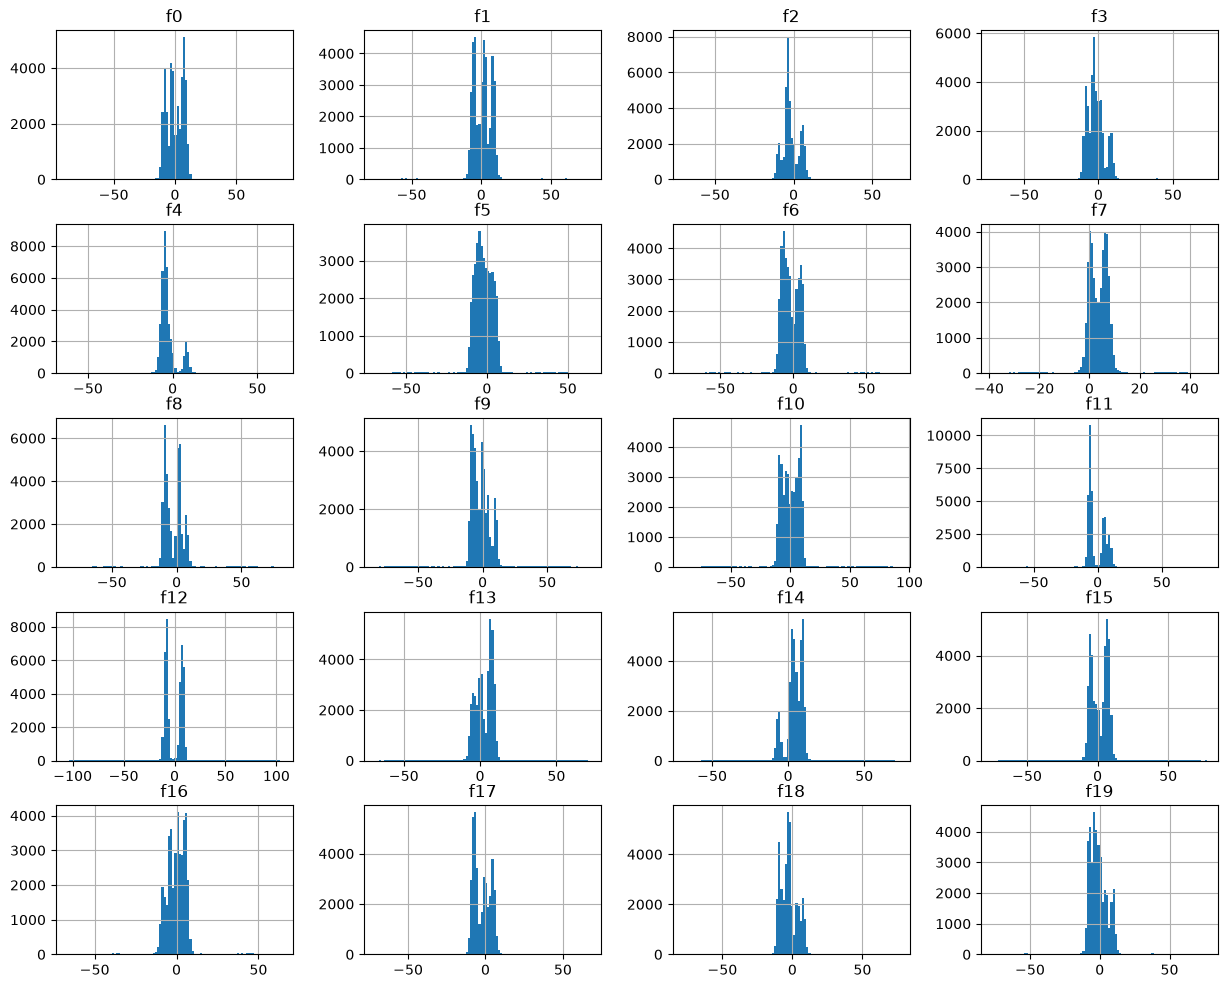

In [12]:
#HIST OF ALL FEATURES
noisy_df.hist(figsize=(15, 12), bins=100)
plt.show()

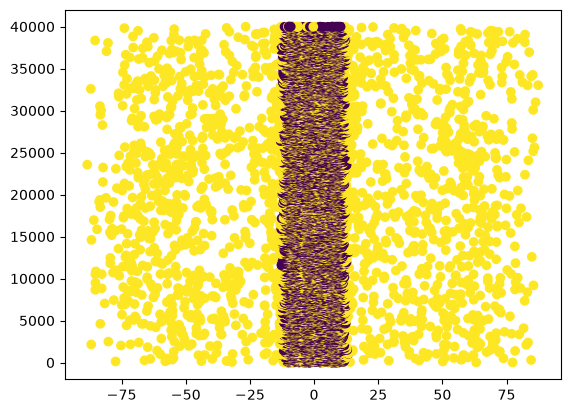

In [9]:
#PLOT FIRST FEATURE
plt.scatter(noisy_df.iloc[:, 0], df.index, c=true_mask)
plt.scatter
plt.show()

In [4]:
def run_iqr(data, iqr_fence, iqr_col_ratio, mask=None):
    suspects = np.zeros(len(data), dtype=int)
    for col in data.columns:
        Q1 = np.percentile(data[col], 25)
        Q3 = np.percentile(data[col], 75)
        IQR = Q3 - Q1
        lower, upper = Q1 - iqr_fence * IQR, Q3 + iqr_fence * IQR
        suspects += (data[col] < lower) | (data[col] > upper)
    flagged = (suspects > len(data.columns) * iqr_col_ratio).to_numpy()
    print(f"IQR: ")
    if mask is not None:
        print(confusion_matrix(mask, flagged, labels=[False, True]))
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_isolation_forest(data, isof_estimators, mask=None):
    model = IsolationForest(n_estimators=isof_estimators, contamination='auto', n_jobs=-1, random_state=rand)
    flagged = model.fit_predict(data) == -1
    print(f"ISOLATION FOREST: ")
    if mask is not None:
        print(confusion_matrix(mask, flagged, labels=[False, True]))
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_kmeans(data, kmeans_init, kmeans_contam, mask=None, kmeans_clusters=None):
    scaled = StandardScaler().fit_transform(data)
    if kmeans_clusters is None:
        kmeans_clusters = 2
        best = 0
        while True:
            k_means = KMeans(n_clusters=kmeans_clusters, random_state=rand, init="k-means++", n_init=20)
            predicted_labels = k_means.fit_predict(X)
            silhouette = silhouette_score(X, predicted_labels)
            if silhouette < best:
                print(f"kmeans cluster amount found: {kmeans_clusters}")
                break
            else:
                kmeans_clusters += 1
                best = silhouette
    kmeans = KMeans(n_clusters=kmeans_clusters, random_state=rand, n_init=kmeans_init, init="k-means++")
    kmeans.fit(scaled)
    distances = np.min(kmeans.transform(scaled), axis=1)
    threshold = np.percentile(distances, (1 - kmeans_contam) * 100)
    flagged = distances > threshold
    print(f"K MEANS: ")
    if mask is not None:
        print(confusion_matrix(mask, flagged, labels=[False, True]))
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_dbscan(data, dbscan_eps, dbscan_min_samp, mask=None):
    scaled = StandardScaler().fit_transform(data)
    dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samp, n_jobs=-1)
    flagged = dbscan.fit_predict(scaled) == -1
    print(f"DBSCAN: ")
    if mask is not None:
        print(confusion_matrix(mask, flagged, labels=[False, True]))
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

def run_lof(data, lof_neighbors, mask=None):
    scaled = StandardScaler().fit_transform(data)
    lof = LocalOutlierFactor(n_neighbors=lof_neighbors, contamination='auto')
    flagged = lof.fit_predict(scaled) == -1
    print(f"LOF: ")
    if mask is not None:
        print(confusion_matrix(mask, flagged, labels=[False, True]))
        print(classification_report(mask, flagged, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
    keep = ~flagged
    data = data.loc[keep]
    if mask is not None:
        mask = mask[keep]
    print(f"entries remaining: {len(data)}")
    print(f"entries flagged: {len(flagged) - len(data)}")
    if mask is not None:
        return data, mask
    else:
        return data

In [5]:
def pipeline(data, mask=None, clusters=None):
    #hyperparam
    iqr_fence = 1.5
    iqr_col_ratio = 0.2
    isof_estimators = 480 
    kmeans_init = 20
    kmeans_contam = 0.01
    dbscan_eps = 3
    dbscan_min_samp = 40
    lof_neighbors = 20

    if mask is None:
        data = run_iqr(data=data, iqr_fence=iqr_fence, iqr_col_ratio=iqr_col_ratio)
        data = run_isolation_forest(data=data, isof_estimators=isof_estimators)
        data = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam)
        data = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp)
        data = run_lof(data=data, lof_neighbors=lof_neighbors)
    else:
        data, mask = run_iqr(data=data, iqr_fence=iqr_fence, iqr_col_ratio=iqr_col_ratio, mask=mask)
        data, mask = run_isolation_forest(data=data, isof_estimators=isof_estimators, mask=mask)
        data, mask = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam, mask=mask)
        data, mask = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp, mask=mask)
        data, mask = run_lof(data=data, lof_neighbors=lof_neighbors, mask=mask)

In [8]:
data = noisy_df.copy()
mask = true_mask.copy()
pipeline(data, mask=mask, clusters=9)

IQR: 
entries remaining: 39865
entries flagged: 135
ISOLATION FOREST: 
entries remaining: 39864
entries flagged: 1
K MEANS: 
entries remaining: 39465
entries flagged: 399
DBSCAN: 
entries remaining: 29005
entries flagged: 10460
LOF: 
entries remaining: 25513
entries flagged: 3492
